# Dự đoán hủy đặt phòng

Đầu vào: `data/cleaned/pandas/hotel_bookings.csv`. Nhãn: `is_canceled` (`1` là hủy). Notebook chia dữ liệu theo thời gian 70/15/15 và so sánh Logistic Regression (SGD), Random Forest, XGBoost, LightGBM và Linear SVM. Các ngưỡng được chọn trên validation; tập test chỉ dùng để đánh giá. Dùng Linear SVM để phù hợp với dữ liệu lớn; ngưỡng của model này áp dụng lên điểm quyết định, không phải xác suất.

Notebook chọn model theo F1 validation. Với model được chọn, notebook nâng ngưỡng nhưng giới hạn mức tăng tỷ lệ bỏ sót hủy trên validation tối đa 8 điểm phần trăm so với ngưỡng F1. Tập test dùng để xem mức đánh đổi thực tế. Model và kết quả được lưu trong `models/cancellation_model.joblib` và `reports/cancellation_model_metrics.json`.

Ngày đặt được ước tính bằng `arrival_date - lead_time`. Do dữ liệu không có ngày tạo booking gốc và thời điểm nhãn được chốt, cách chia theo thời gian là xấp xỉ.


In [1]:
# 1. Thư viện và đường dẫn dữ liệu

from pathlib import Path
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

DATA_RELATIVE_PATH = Path("data/cleaned/pandas/hotel_bookings.csv")
ROOT_CANDIDATES = [
    Path("/workspace"),
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
]

DATA_PATH = next(
    (root / DATA_RELATIVE_PATH for root in ROOT_CANDIDATES
     if (root / DATA_RELATIVE_PATH).is_file()),
    None,
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy data/cleaned/pandas/hotel_bookings.csv. "
        "Hãy tải file Pandas đã làm sạch về đúng thư mục data/cleaned/pandas/ "
        "rồi mở lại notebook."
    )

PROJECT_ROOT = DATA_PATH.parents[3]
print(f"File dữ liệu: {DATA_PATH}")


File dữ liệu: /workspace/data/cleaned/pandas/hotel_bookings.csv


In [2]:
# 2. Chọn feature và chuẩn bị dữ liệu

TARGET = "is_canceled"
SPLIT_DATE_COLUMN = "arrival_date"

NUMERIC_FEATURES = [
    "lead_time",
    "arrival_date_year",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
]

CATEGORICAL_FEATURES = [
    "hotel",
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "deposit_type",
    "agent",
    "company",
    "customer_type",
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
REQUIRED_COLUMNS = [TARGET, SPLIT_DATE_COLUMN] + FEATURES

file_columns = set(pd.read_csv(DATA_PATH, nrows=0).columns.str.strip())
missing_columns = sorted(set(REQUIRED_COLUMNS) - file_columns)
if missing_columns:
    raise ValueError(f"File dữ liệu đang thiếu các cột cần dùng: {missing_columns}")

category_types = {column: "string" for column in CATEGORICAL_FEATURES}
category_types[SPLIT_DATE_COLUMN] = "string"
data = pd.read_csv(
    DATA_PATH,
    usecols=REQUIRED_COLUMNS,
    dtype=category_types,
    low_memory=False,
)
data.columns = data.columns.str.strip()

rows_before = len(data)
data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")
valid_target = data[TARGET].isin([0, 1])
invalid_target_rows = int((~valid_target).sum())
data = data.loc[valid_target].copy()
y = data.pop(TARGET).astype("int8")
arrival_dates = pd.to_datetime(data.pop(SPLIT_DATE_COLUMN), errors="coerce")
X = data[FEATURES].copy()

for column in NUMERIC_FEATURES:
    X[column] = pd.to_numeric(X[column], errors="coerce")
    X[column] = X[column].replace([np.inf, -np.inf], np.nan)

for column in CATEGORICAL_FEATURES:
    X[column] = X[column].astype(object)
    X[column] = X[column].where(pd.notna(X[column]), np.nan)

lead_days = pd.to_numeric(X["lead_time"], errors="coerce")
booking_dates = arrival_dates - pd.to_timedelta(lead_days, unit="D", errors="coerce")
valid_booking_date = booking_dates.notna()
rows_missing_booking_date = int((~valid_booking_date).sum())
X = X.loc[valid_booking_date].copy()
y = y.loc[valid_booking_date]
booking_dates = booking_dates.loc[valid_booking_date]

print(f"Số dòng ban đầu: {rows_before:,}")
print(f"Bỏ do nhãn thiếu/không hợp lệ: {invalid_target_rows:,}")
print(f"Bỏ do không ước tính được ngày đặt: {rows_missing_booking_date:,}")
print(f"Số dòng dùng được: {len(X):,}")

target_counts = y.value_counts().reindex([0, 1], fill_value=0)
target_summary = pd.DataFrame({
    "Trạng thái": ["Không hủy", "Đã hủy"],
    "Số dòng": target_counts.to_numpy(),
    "Tỷ lệ (%)": (target_counts.to_numpy() / len(y) * 100).round(2),
})
display(target_summary)


Số dòng ban đầu: 1,329,545
Bỏ do nhãn thiếu/không hợp lệ: 0
Bỏ do không ước tính được ngày đặt: 0
Số dòng dùng được: 1,329,545


,Trạng thái,Số dòng,Tỷ lệ (%)
0,Không hủy,848380,63.81
1,Đã hủy,481165,36.19


In [3]:
# 3. Chia train, validation, test theo thời gian

train_cutoff = booking_dates.quantile(0.70)
validation_cutoff = booking_dates.quantile(0.85)

train_mask = booking_dates <= train_cutoff
validation_mask = (booking_dates > train_cutoff) & (booking_dates <= validation_cutoff)
test_mask = booking_dates > validation_cutoff

X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_validation, y_validation = X.loc[validation_mask], y.loc[validation_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]

splits = {
    "Train": booking_dates.loc[train_mask],
    "Validation": booking_dates.loc[validation_mask],
    "Test": booking_dates.loc[test_mask],
}

for name, dates in splits.items():
    if dates.empty:
        raise ValueError(f"Tập {name} rỗng. Cần kiểm tra phạm vi ngày trong dữ liệu.")
    print(
        f"{name}: {len(dates):,} dòng | "
        f"{dates.min().date()} đến {dates.max().date()}"
    )

if any(labels.nunique() < 2 for labels in [y_train, y_validation, y_test]):
    raise ValueError("Một tập chỉ có một nhãn; không thể đánh giá phân loại ổn định.")


Train: 932,168 dòng | 2013-06-24 đến 2016-11-08
Validation: 198,504 dòng | 2016-11-09 đến 2017-02-04
Test: 198,873 dòng | 2017-02-05 đến 2017-08-31


In [4]:
# 4. Tiền xử lý và huấn luyện các model

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
])

positive_count = int(y_train.sum())
negative_count = int((y_train == 0).sum())

classifiers = {
    "Logistic Regression (SGD)": SGDClassifier(
        loss="log_loss",
        class_weight="balanced",
        max_iter=100,
        tol=1e-3,
        random_state=42,
        n_jobs=-1,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=40,
        max_depth=14,
        min_samples_leaf=100,
        max_features="sqrt",
        max_samples=0.5,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
    ),
    "XGBoost": XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=negative_count / positive_count,
        reg_lambda=1.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=42,
        verbosity=0,
    ),
    "LightGBM": LGBMClassifier(
        objective="binary",
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=100,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        class_weight="balanced",
        reg_lambda=1.0,
        n_jobs=-1,
        random_state=42,
        verbosity=-1,
    ),
    "Linear SVM": LinearSVC(
        C=0.1,
        class_weight="balanced",
        dual="auto",
        max_iter=2000,
        random_state=42,
    ),
}

models = {
    name: Pipeline(steps=[
        ("preprocessing", clone(preprocessor)),
        ("classifier", classifier),
    ])
    for name, classifier in classifiers.items()
}

def get_model_score(candidate, features):
    classifier = candidate.named_steps["classifier"]
    if hasattr(classifier, "predict_proba"):
        return candidate.predict_proba(features)[:, 1]
    return candidate.decision_function(features)


training_seconds_by_model = {}
validation_scores = {}

for name, candidate in models.items():
    print(f"Đang huấn luyện: {name}")
    started = time.perf_counter()
    candidate.fit(X_train, y_train)
    training_seconds_by_model[name] = time.perf_counter() - started
    validation_scores[name] = get_model_score(candidate, X_validation)
    print(f"Thời gian: {training_seconds_by_model[name]:.2f} giây")


Đang huấn luyện: Logistic Regression (SGD)


Thời gian: 4.32 giây
Đang huấn luyện: Random Forest


Thời gian: 7.51 giây
Đang huấn luyện: XGBoost


Thời gian: 6.46 giây
Đang huấn luyện: LightGBM


Thời gian: 7.78 giây
Đang huấn luyện: Linear SVM


Thời gian: 38.47 giây


In [5]:
# 5. Chọn ngưỡng và chọn model bằng validation

validation_metrics_by_model = {}
decision_thresholds = {}

for name, score in validation_scores.items():
    precision_values, recall_values, thresholds = precision_recall_curve(
        y_validation,
        score,
    )
    validation_f1_values = (
        2 * precision_values[:-1] * recall_values[:-1]
        / (precision_values[:-1] + recall_values[:-1] + 1e-12)
    )
    best_index = int(np.argmax(validation_f1_values))
    threshold = float(thresholds[best_index])
    prediction = (score >= threshold).astype("int8")

    decision_thresholds[name] = threshold
    validation_metrics_by_model[name] = {
        "decision_threshold": round(threshold, 4),
        "validation_precision": round(float(precision_score(
            y_validation, prediction, zero_division=0)), 4),
        "validation_recall": round(float(recall_score(
            y_validation, prediction, zero_division=0)), 4),
        "validation_f1": round(float(f1_score(
            y_validation, prediction, zero_division=0)), 4),
        "validation_roc_auc": round(float(roc_auc_score(
            y_validation, score)), 4),
        "validation_average_precision": round(float(average_precision_score(
            y_validation, score)), 4),
    }

validation_comparison = pd.DataFrame([
    {"model": name, **scores}
    for name, scores in validation_metrics_by_model.items()
]).sort_values("validation_f1", ascending=False)

display(validation_comparison)

selected_model_name = str(validation_comparison.iloc[0]["model"])
selected_model = models[selected_model_name]
decision_threshold = decision_thresholds[selected_model_name]
print(f"Model được chọn theo F1 validation: {selected_model_name}")


,model,decision_threshold,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision
3,LightGBM,0.5398,0.6481,0.8850,0.7482,0.8893,0.8561
2,XGBoost,0.5071,0.6357,0.9035,0.7463,0.8865,0.8520
1,Random Forest,0.4555,0.6420,0.8727,0.7398,0.8703,0.8375
4,Linear SVM,-0.0016,0.6245,0.8419,0.7171,0.8614,0.8263
0,Logistic Regression (SGD),0.4778,0.6195,0.8503,0.7168,0.8595,0.8219


Model được chọn theo F1 validation: LightGBM


In [6]:
# 6. So sánh kết quả cuối trên test

# Các model dùng ngưỡng F1 đã chọn riêng trên validation. Linear SVM dùng điểm quyết định. Phần ngưỡng vận hành của model tốt nhất được đánh giá riêng ở mục 9.

test_scores = {}
test_predictions = {}
test_rows = []

for name, candidate in models.items():
    score = get_model_score(candidate, X_test)
    threshold = decision_thresholds[name]
    prediction = (score >= threshold).astype("int8")
    test_scores[name] = score
    test_predictions[name] = prediction

    validation_metrics = validation_metrics_by_model[name]
    test_rows.append({
        "model": name,
        "selected_on_validation": name == selected_model_name,
        "training_seconds": round(float(training_seconds_by_model[name]), 2),
        "decision_threshold": validation_metrics["decision_threshold"],
        "validation_f1": validation_metrics["validation_f1"],
        "validation_roc_auc": validation_metrics["validation_roc_auc"],
        "validation_average_precision": validation_metrics["validation_average_precision"],
        "test_accuracy": round(float(accuracy_score(y_test, prediction)), 4),
        "test_precision_cancelled": round(float(precision_score(
            y_test, prediction, zero_division=0)), 4),
        "test_recall_cancelled": round(float(recall_score(
            y_test, prediction, zero_division=0)), 4),
        "test_f1_cancelled": round(float(f1_score(
            y_test, prediction, zero_division=0)), 4),
        "test_roc_auc": round(float(roc_auc_score(y_test, score)), 4),
        "test_average_precision": round(float(average_precision_score(
            y_test, score)), 4),
    })

test_comparison = pd.DataFrame(test_rows).sort_values(
    "selected_on_validation",
    ascending=False,
)
display(test_comparison)


,model,selected_on_validation,training_seconds,decision_threshold,validation_f1,validation_roc_auc,validation_average_precision,test_accuracy,test_precision_cancelled,test_recall_cancelled,test_f1_cancelled,test_roc_auc,test_average_precision
3,LightGBM,True,7.78,0.5398,0.7482,0.8893,0.8561,0.7316,0.5293,0.7854,0.6324,0.8225,0.6454
0,Logistic Regression (SGD),False,4.32,0.4778,0.7168,0.8595,0.8219,0.6725,0.4654,0.7650,0.5787,0.7684,0.5584
1,Random Forest,False,7.51,0.4555,0.7398,0.8703,0.8375,0.7249,0.5232,0.7234,0.6072,0.7894,0.6032
2,XGBoost,False,6.46,0.5071,0.7463,0.8865,0.8520,0.7249,0.5207,0.8092,0.6336,0.8178,0.6326
4,Linear SVM,False,38.47,-0.0016,0.7171,0.8614,0.8263,0.6817,0.4737,0.7425,0.5784,0.7717,0.5709


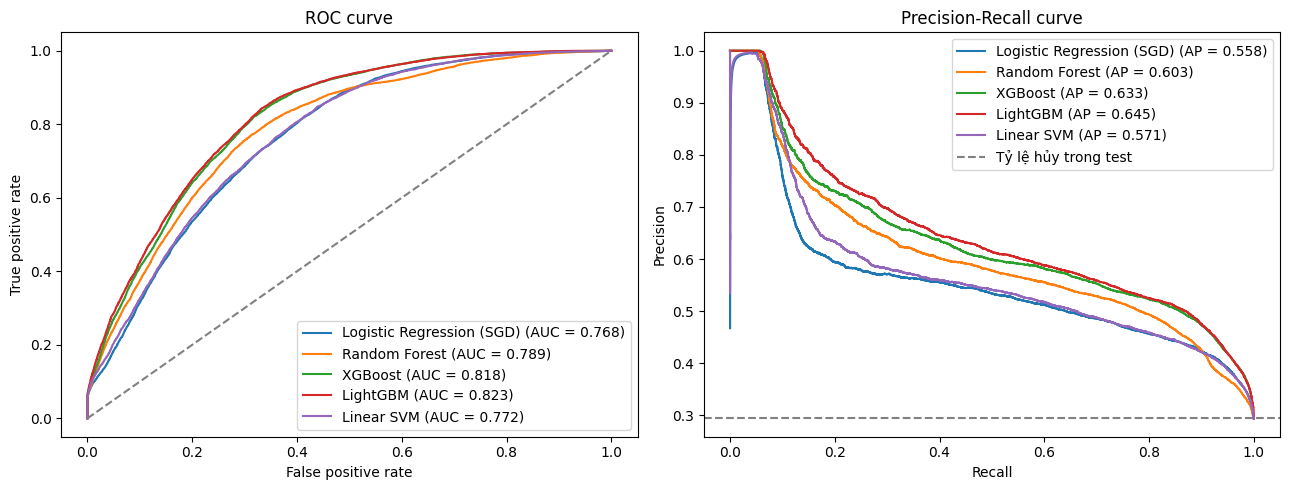

In [7]:
# 7. Đường cong ROC và Precision-Recall trên test

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, score in test_scores.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, score)
    roc_auc = roc_auc_score(y_test, score)
    axes[0].plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{name} (AUC = {roc_auc:.3f})",
    )

    precision_values, recall_values, _ = precision_recall_curve(y_test, score)
    average_precision = average_precision_score(y_test, score)
    axes[1].plot(
        recall_values,
        precision_values,
        label=f"{name} (AP = {average_precision:.3f})",
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title("ROC curve")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend(loc="lower right")

axes[1].axhline(
    y=float(y_test.mean()),
    linestyle="--",
    color="gray",
    label="Tỷ lệ hủy trong test",
)
axes[1].set_title("Precision-Recall curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


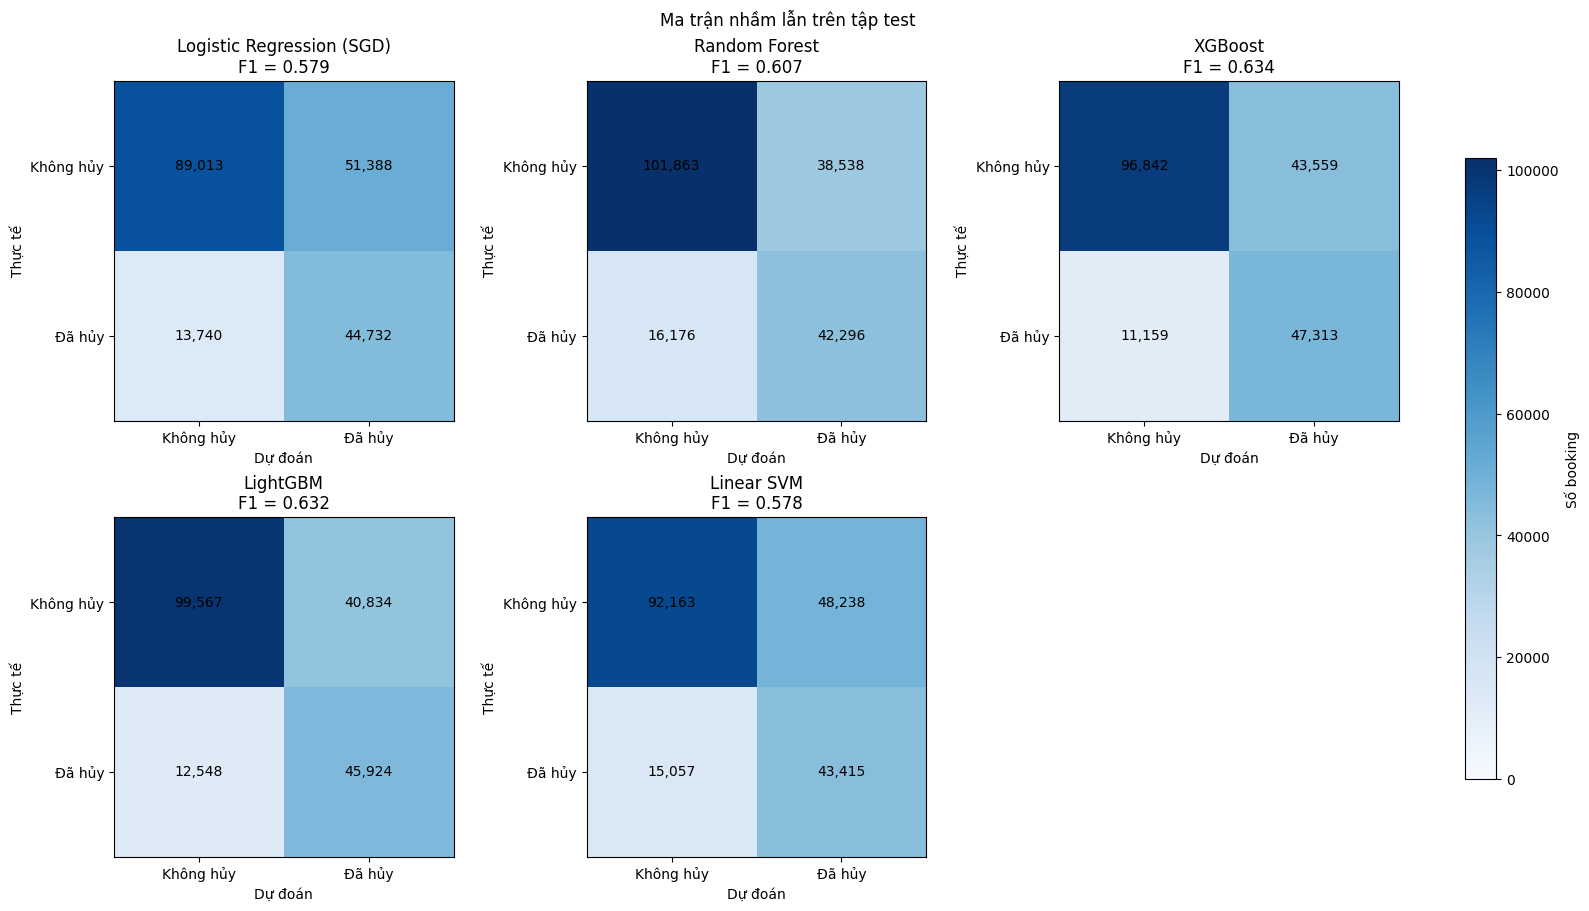

In [8]:
# 8. Ma trận nhầm lẫn của các model trên test

# Ma trận dùng ngưỡng F1 validation của từng model. Hàng là nhãn thực tế, cột là dự đoán.

confusion_matrices = {
    name: confusion_matrix(y_test, prediction, labels=[0, 1])
    for name, prediction in test_predictions.items()
}
color_max = max(matrix.max() for matrix in confusion_matrices.values())

fig, axes = plt.subplots(2, 3, figsize=(16, 9), layout="constrained")
axes = axes.ravel()
for ax in axes[len(confusion_matrices):]:
    ax.set_visible(False)

for ax, (name, matrix) in zip(axes, confusion_matrices.items()):
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=color_max)
    test_f1 = float(
        test_comparison.loc[test_comparison["model"] == name, "test_f1_cancelled"].iloc[0]
    )
    ax.set_title(f"{name}\nF1 = {test_f1:.3f}")
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
    ax.set_xticks([0, 1], ["Không hủy", "Đã hủy"])
    ax.set_yticks([0, 1], ["Không hủy", "Đã hủy"])

    for row in range(2):
        for column in range(2):
            ax.text(
                column, row, f"{matrix[row, column]:,}",
                ha="center", va="center", color="black",
            )

fig.colorbar(image, ax=[ax for ax in axes if ax.get_visible()], label="Số booking", shrink=0.8)
fig.suptitle("Ma trận nhầm lẫn trên tập test")
plt.show()


,Ngưỡng,Giá trị,FP,FN,Tỷ lệ lỗi loại I,Tỷ lệ lỗi loại II,Precision hủy,Recall hủy,Balanced accuracy,F1 hủy
0,Ngưỡng F1 tối đa,0.5398,40834,12548,0.2908,0.2146,0.5293,0.7854,0.7473,0.6324
1,Ngưỡng tăng để so sánh,0.6045,29349,19536,0.2090,0.3341,0.5702,0.6659,0.7284,0.6143


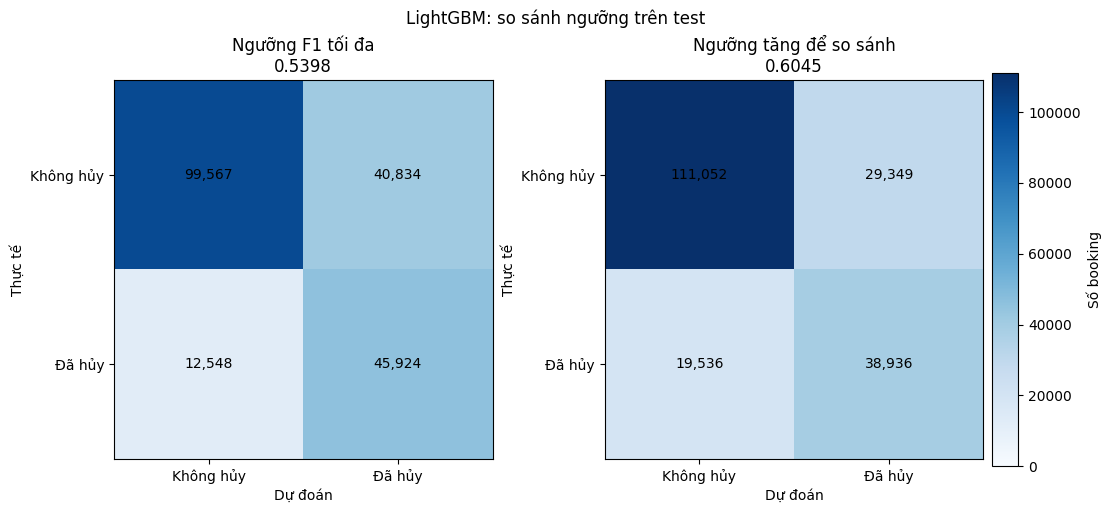

              precision    recall  f1-score   support

   Không hủy      0.888     0.709     0.789    140401
      Đã hủy      0.529     0.785     0.632     58472

    accuracy                          0.732    198873
   macro avg      0.709     0.747     0.711    198873
weighted avg      0.783     0.732     0.743    198873



In [9]:
# 9. Dùng ngưỡng F1 tối đa và so sánh với ngưỡng tăng

baseline_threshold = decision_thresholds[selected_model_name]
validation_fpr, validation_tpr, validation_thresholds = roc_curve(
    y_validation, validation_scores[selected_model_name]
)

baseline_validation_prediction = (
    validation_scores[selected_model_name] >= baseline_threshold
).astype("int8")
_, baseline_validation_fp, baseline_validation_fn, baseline_validation_tp = confusion_matrix(
    y_validation, baseline_validation_prediction, labels=[0, 1]
).ravel()
baseline_validation_fnr = baseline_validation_fn / (
    baseline_validation_fn + baseline_validation_tp
)

MAX_FNR_INCREASE = 0.08
validation_false_negative_rate = 1 - validation_tpr
candidate_indices = np.flatnonzero(
    np.isfinite(validation_thresholds)
    & (validation_thresholds > baseline_threshold)
    & (validation_false_negative_rate <= baseline_validation_fnr + MAX_FNR_INCREASE)
)
if len(candidate_indices):
    comparison_index = candidate_indices[
        np.argmax(validation_thresholds[candidate_indices])
    ]
    comparison_threshold = float(validation_thresholds[comparison_index])
else:
    comparison_index = None
    comparison_threshold = baseline_threshold

# Model cuối cùng dùng ngưỡng F1 cao nhất; ngưỡng tăng chỉ dùng để so sánh.
decision_threshold = baseline_threshold

def summarize_threshold(y_true, score, threshold, label):
    prediction = (score >= threshold).astype("int8")
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    false_positive_rate = fp / (fp + tn) if fp + tn else 0.0
    false_negative_rate = fn / (fn + tp) if fn + tp else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "Ngưỡng": label,
        "Giá trị": round(float(threshold), 4),
        "FP": int(fp),
        "FN": int(fn),
        "Tỷ lệ lỗi loại I": round(float(false_positive_rate), 4),
        "Tỷ lệ lỗi loại II": round(float(false_negative_rate), 4),
        "Precision hủy": round(float(precision_score(y_true, prediction, zero_division=0)), 4),
        "Recall hủy": round(float(recall), 4),
        "Balanced accuracy": round(float((specificity + recall) / 2), 4),
        "F1 hủy": round(float(f1_score(y_true, prediction, zero_division=0)), 4),
        "matrix": confusion_matrix(y_true, prediction, labels=[0, 1]),
    }

selected_test_score = test_scores[selected_model_name]
baseline_result = summarize_threshold(
    y_test, selected_test_score, baseline_threshold, "Ngưỡng F1 tối đa"
)
raised_result = summarize_threshold(
    y_test, selected_test_score, comparison_threshold, "Ngưỡng tăng để so sánh"
)
threshold_comparison = pd.DataFrame([
    {key: value for key, value in result.items() if key != "matrix"}
    for result in [baseline_result, raised_result]
])
display(threshold_comparison)

threshold_matrices = [baseline_result["matrix"], raised_result["matrix"]]
threshold_color_max = max(matrix.max() for matrix in threshold_matrices)
fig = plt.figure(figsize=(11, 5), layout="constrained")
grid = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.07])
axes = [fig.add_subplot(grid[0, index]) for index in range(2)]
colorbar_axis = fig.add_subplot(grid[0, 2])
for ax, result in zip(axes, [baseline_result, raised_result]):
    matrix = result["matrix"]
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=threshold_color_max)
    ax.set_title(f"{result['Ngưỡng']}\n{result['Giá trị']:.4f}")
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
    ax.set_xticks([0, 1], ["Không hủy", "Đã hủy"])
    ax.set_yticks([0, 1], ["Không hủy", "Đã hủy"])
    for row in range(2):
        for column in range(2):
            ax.text(column, row, f"{matrix[row, column]:,}", ha="center", va="center")
fig.colorbar(image, cax=colorbar_axis, label="Số booking")
fig.suptitle(f"{selected_model_name}: so sánh ngưỡng trên test")
plt.show()

final_prediction = (selected_test_score >= decision_threshold).astype("int8")
operational_metrics = {
    "model": selected_model_name,
    "split_method": "chronological by estimated booking date",
    "rows_used": int(len(X)),
    "train_rows": int(len(X_train)),
    "validation_rows": int(len(X_validation)),
    "test_rows": int(len(X_test)),
    "decision_threshold": round(float(decision_threshold), 4),
    "baseline_f1_threshold": round(float(baseline_threshold), 4),
    "threshold_selection": "maximum validation F1",
    "comparison_threshold": round(float(comparison_threshold), 4),
    "comparison_threshold_max_validation_fnr_increase": MAX_FNR_INCREASE,
    "validation_f1": validation_metrics_by_model[selected_model_name]["validation_f1"],
    "test_cancellation_rate": round(float(y_test.mean()), 4),
    "accuracy": round(float(accuracy_score(y_test, final_prediction)), 4),
    "precision_cancelled": round(float(precision_score(y_test, final_prediction, zero_division=0)), 4),
    "recall_cancelled": round(float(recall_score(y_test, final_prediction, zero_division=0)), 4),
    "f1_cancelled": round(float(f1_score(y_test, final_prediction, zero_division=0)), 4),
    "false_positive_rate": baseline_result["Tỷ lệ lỗi loại I"],
    "false_negative_rate": baseline_result["Tỷ lệ lỗi loại II"],
    "balanced_accuracy": baseline_result["Balanced accuracy"],
    "roc_auc": round(float(roc_auc_score(y_test, selected_test_score)), 4),
    "average_precision": round(float(average_precision_score(y_test, selected_test_score)), 4),
    "training_seconds": round(float(training_seconds_by_model[selected_model_name]), 2),
}
print(classification_report(
    y_test, final_prediction, labels=[0, 1],
    target_names=["Không hủy", "Đã hủy"], zero_division=0, digits=3,
))


In [10]:
# 10. Lưu model và báo cáo so sánh

MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "cancellation_model.joblib"
REPORT_PATH = REPORT_DIR / "cancellation_model_metrics.json"

model_info = {
    **operational_metrics,
    "target": TARGET,
    "features": FEATURES,
    "models_compared": list(models.keys()),
    "selected_by": "highest validation F1",
    "model_comparison_at_f1_thresholds": test_comparison.to_dict(orient="records"),
    "threshold_test_comparison": threshold_comparison.to_dict(orient="records"),
    "time_split": "estimated_booking_date = arrival_date - lead_time",
    "train_booking_date_range": [
        splits["Train"].min().date().isoformat(),
        splits["Train"].max().date().isoformat(),
    ],
    "validation_booking_date_range": [
        splits["Validation"].min().date().isoformat(),
        splits["Validation"].max().date().isoformat(),
    ],
    "test_booking_date_range": [
        splits["Test"].min().date().isoformat(),
        splits["Test"].max().date().isoformat(),
    ],
    "excluded_columns_to_avoid_target_or_post_booking_leakage": [
        "reservation_status",
        "reservation_status_date",
        "booking_changes",
        "assigned_room_type",
        "days_in_waiting_list",
        "adr",
        "required_car_parking_spaces",
        "total_of_special_requests",
    ],
}

joblib.dump({
    "pipeline": selected_model,
    "decision_threshold": decision_threshold,
    "baseline_f1_threshold": baseline_threshold,
    "threshold_selection": operational_metrics["threshold_selection"],
    "target": TARGET,
    "model_name": selected_model_name,
}, MODEL_PATH, compress=3)
REPORT_PATH.write_text(
    json.dumps(model_info, ensure_ascii=False, indent=2, default=lambda value: value.item()),
    encoding="utf-8",
)

print(f"Đã lưu model: {MODEL_PATH}")
print(f"Đã lưu kết quả: {REPORT_PATH}")

Đã lưu model: /workspace/models/cancellation_model.joblib
Đã lưu kết quả: /workspace/reports/cancellation_model_metrics.json
